# 11 - Baselines & wind-aware ablation (RG6 evidence)

Built on the **v2 pipeline** (notebook 09): identical 26 features, volatility-weighted
Huber loss, 48h/24h windows, AdamW + cosine schedule, early stop patience 12. The
**wind-aware graph is the only variable**.

| model | encoder graph | forecast graph |
|---|---|---|
| WA-TGCN (dynamic) | wind A(t) | wind climatology A_fc |
| Static-GCN | `static_adj_matrix.npy` (distance, 12 km) | same static matrix |
| No-graph | none (per-station) | none | 
| Persistence | - | last observed value, repeated 24 h |

Seeds 42/7/123/2024/999 throughout. `dynamic` reuses the trained `watgcn_v2_seed*.pt`
checkpoints (the ablation model in `dynamic` mode is byte-identical to notebook 09's
class); `static` and `no-graph` train fresh. ~45-60 min on an RTX 3050.

Outputs: `ecotwin_outputs/results/baselines_comparison.csv`, `baselines_metrics.json`,
`ecotwin_outputs/plots/baselines_*.png`. Nothing else is touched.

In [2]:
import os, json, time, copy, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
SCALER_DIR  = os.path.join(OUT, 'scalers')
MODEL_DIR   = os.path.join(OUT, 'models')
RESULTS_DIR = os.path.join(OUT, 'results')
PLOT_DIR    = os.path.join(OUT, 'plots')

DATASET_CSV      = os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv')
DYNAMIC_ADJ_PATH = os.path.join(V2_DIR, 'dynamic_adj_matrix.npy')
STATIC_ADJ_PATH  = os.path.join(V2_DIR, 'static_adj_matrix.npy')
STATIONS_EXCEL   = os.path.join(V2_DIR, 'Delhi_list_v2.xlsx')
CLIM_GRID_PATH   = os.path.join(V2_DIR, 'v2_clim_grid.npy')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
INPUT_WINDOW, HORIZON = 48, 24
BATCH_SIZE = 16
LOSS_VOL_ALPHA = 1.0
SEEDS = [42, 7, 123, 2024, 999]
THRESHOLD_KM = 12.0

cfg = json.load(open(os.path.join(MODEL_DIR, 'v2_config.json')))
FEATURE_COLS = cfg['feature_cols']; TIME_COLS = cfg['time_cols']
F = cfg['in_features']; HIDDEN_DIM = cfg['hidden_dim']; GRU_LAYERS = cfg['gru_layers']
ATTN_HEADS = cfg['attn_heads']; DROPOUT = cfg['dropout']; GCN_HOPS = cfg['gcn_hops']

print(f'Device {DEVICE} | F={F} | seeds {SEEDS}')

Device cuda | F=26 | seeds [42, 7, 123, 2024, 999]


In [3]:
df = pd.read_csv(DATASET_CSV, parse_dates=['Timestamp'])
df['Station'] = df['Station'].str.strip()
df = df.sort_values(['Station', 'Timestamp']).reset_index(drop=True)

df_st = pd.read_excel(STATIONS_EXCEL)
df_st.columns = df_st.columns.str.strip().str.lower()
df_st['station'] = df_st['station'].str.strip()
station_names = df_st['station'].tolist()
lats = df_st['latitude'].values.astype(float)
lons = df_st['longitude'].values.astype(float)
N = len(station_names)

timestamps = np.array(sorted(df['Timestamp'].unique())); T = len(timestamps)
dyn_adj    = np.load(DYNAMIC_ADJ_PATH).astype(np.float32)
static_adj = np.load(STATIC_ADJ_PATH).astype(np.float32)
np.fill_diagonal(static_adj, 0.0)                                # model adds self-loops itself

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arctan2(np.sqrt(a), np.sqrt(1-a))
dist_matrix = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            dist_matrix[i, j] = haversine_km(lats[i], lons[i], lats[j], lons[j])
within_threshold = (dist_matrix > 0) & (dist_matrix <= THRESHOLD_KM)
dir_u = np.zeros((N, N)); dir_v = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            de = (lons[j]-lons[i]) * np.cos(np.radians(lats[i]))
            dn = lats[j]-lats[i]; nr = np.hypot(de, dn)
            if nr > 0:
                dir_u[i, j], dir_v[i, j] = de/nr, dn/nr
print(f'N={N} T={T} | dyn_adj {dyn_adj.shape} | static edges {int((static_adj>0).sum())}')

N=37 T=19921 | dyn_adj (19921, 37, 37) | static edges 508


In [4]:
# identical feature recipe to 09_model_v2 / 10_export_dashboard_v2
BASE_FEATS = ['pm2.5','pm10','no2','so2','co','o3','rh','at','u_wind','v_wind']
g = df.groupby('Station', sort=False)
df['wspd'] = np.hypot(df['u_wind'], df['v_wind'])
df['pm_roll6_mean']  = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).mean())
df['pm_roll6_std']   = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).std()).fillna(0.0)
df['pm_roll24_mean'] = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).mean())
df['pm_roll24_std']  = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).std()).fillna(0.0)
df['pm_delta3']      = g['pm2.5'].transform(lambda s: s - s.shift(3)).fillna(0.0)
tsg = df.groupby('Timestamp', sort=False)['pm2.5']
df['city_mean_pm']  = tsg.transform('mean')
df['city_max_pm']   = tsg.transform('max')
df['pm_minus_city'] = df['pm2.5'] - df['city_mean_pm']
hh = df['Timestamp'].dt.hour; dow = df['Timestamp'].dt.dayofweek; mon = df['Timestamp'].dt.month
df['hour_sin'] = np.sin(2*np.pi*hh/24);      df['hour_cos'] = np.cos(2*np.pi*hh/24)
df['dow_sin']  = np.sin(2*np.pi*dow/7);      df['dow_cos']  = np.cos(2*np.pi*dow/7)
df['mon_sin']  = np.sin(2*np.pi*(mon-1)/12); df['mon_cos']  = np.cos(2*np.pi*(mon-1)/12)
df['is_weekend'] = (dow >= 5).astype(float)

built = (BASE_FEATS +
    ['wspd','pm_roll6_mean','pm_roll6_std','pm_roll24_mean','pm_roll24_std','pm_delta3',
     'city_mean_pm','city_max_pm','pm_minus_city',
     'hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend'])
assert built == FEATURE_COLS
TIME_IDX = [FEATURE_COLS.index(c) for c in TIME_COLS]
WSPD_IDX = FEATURE_COLS.index('wspd')

X_full = np.zeros((T, N, F), dtype=np.float32)
for fi, col in enumerate(FEATURE_COLS):
    wide = df.pivot_table(index='Timestamp', columns='Station', values=col).reindex(columns=station_names)
    X_full[:, :, fi] = np.nan_to_num(wide.values.astype(np.float32))
Y_raw = X_full[:, :, 0].copy()
wspd_raw = X_full[:, :, WSPD_IDX].copy()                         # raw wind speed for the regime split
print(f'X_full {X_full.shape}  NaNs {int(np.isnan(X_full).sum())}')

X_full (19921, 37, 26)  NaNs 0


In [5]:
feat_scaler = pickle.load(open(os.path.join(SCALER_DIR, 'v2_feature_scaler.pkl'), 'rb'))
log_scaler  = pickle.load(open(os.path.join(SCALER_DIR, 'v2_log_scaler.pkl'), 'rb'))
Xs_full = feat_scaler.transform(X_full.reshape(-1, F)).reshape(T, N, F).astype(np.float32)
def from_log(a):
    return np.expm1(log_scaler.inverse_transform(a.reshape(-1, 1)).reshape(a.shape))
def to_log(a):
    return log_scaler.transform(np.log1p(np.clip(a, 0, None)).reshape(-1, 1)).reshape(a.shape).astype(np.float32)
Yl_full = to_log(Y_raw)
del X_full

clim_grid = np.load(CLIM_GRID_PATH)
def compute_At_vec(u, v, eps=1e-6):
    al = u[:, None]*dir_u + v[:, None]*dir_v
    A = np.where(within_threshold & (al > 0.0), al/(dist_matrix + eps), 0.0).astype(np.float32)
    rs = A.sum(1, keepdims=True); rs[rs == 0] = 1.0
    return A / rs
mo_arr = pd.DatetimeIndex(timestamps).month.values - 1
ho_arr = pd.DatetimeIndex(timestamps).hour.values
dyn_clim = np.zeros((T, N, N), dtype=np.float32)
for t in range(T):
    uv = clim_grid[mo_arr[t], ho_arr[t]]
    dyn_clim[t] = compute_At_vec(uv[:, 0], uv[:, 1])
print('scaled with saved v2 scalers | dyn_clim', dyn_clim.shape)

scaled with saved v2 scalers | dyn_clim (19921, 37, 37)


In [6]:
train_end_idx = int(T * 0.70); val_end_idx = int(T * 0.85)
def split_starts(lo, hi):
    return np.arange(lo, lo + (hi - lo) - (INPUT_WINDOW + HORIZON) + 1)
train_starts = split_starts(0, train_end_idx)
val_starts   = split_starts(train_end_idx, val_end_idx)
test_starts  = split_starts(val_end_idx, T)
print(f'windows -- train {len(train_starts):,} | val {len(val_starts):,} | test {len(test_starts):,}')

def window_swing(starts):
    return np.array([(Y_raw[gg+INPUT_WINDOW:gg+INPUT_WINDOW+HORIZON].max(0) -
                      Y_raw[gg+INPUT_WINDOW:gg+INPUT_WINDOW+HORIZON].min(0)).mean()
                     for gg in starts], dtype=np.float32)
tr_swing = window_swing(train_starts); med = float(np.median(tr_swing))
tr_w = np.clip(1.0 + LOSS_VOL_ALPHA * (tr_swing / (med + 1e-6)), 0.5, 4.0).astype(np.float32)
tr_w *= len(tr_w) / tr_w.sum()

class AblateDS(Dataset):
    def __init__(self, starts, mode, weights=None):
        self.s = np.asarray(starts, np.int64); self.mode = mode
        self.w = (weights if weights is not None else np.ones(len(self.s), np.float32)).astype(np.float32)
    def __len__(self):
        return len(self.s)
    def __getitem__(self, k):
        gg = int(self.s[k]); i1 = gg + INPUT_WINDOW; i2 = i1 + HORIZON
        X   = torch.from_numpy(Xs_full[gg:i1].copy())
        tf  = torch.from_numpy(np.ascontiguousarray(Xs_full[i1:i2, 0, :][:, TIME_IDX]))
        anc = torch.from_numpy(Yl_full[i1-1].copy())
        y   = torch.from_numpy(Yl_full[i1:i2].copy())
        w   = torch.tensor(self.w[k], dtype=torch.float32)
        if self.mode == 'dynamic':
            At  = torch.from_numpy(dyn_adj[gg:i1].copy())
            Afc = torch.from_numpy(dyn_clim[i1:i2].copy())
        else:
            At = torch.zeros(1); Afc = torch.zeros(1)             # unused by static / none
        return X, At, Afc, tf, anc, y, w

def loaders(mode):
    return (DataLoader(AblateDS(train_starts, mode, tr_w), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0),
            DataLoader(AblateDS(val_starts,   mode),        batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
            DataLoader(AblateDS(test_starts,  mode),        batch_size=BATCH_SIZE, shuffle=False, num_workers=0))
print('datasets ready')

windows -- train 13,873 | val 2,917 | test 2,918
datasets ready


In [7]:
class WATGCNAblate(nn.Module):
    """graph_mode: 'dynamic' (== notebook 09 WATGCNv2) | 'static' | 'none'."""
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads, forecast_horizon,
                 n_stations, dropout=0.2, n_time=7, gcn_hops=2, graph_mode='dynamic', static_adj=None):
        super().__init__()
        H = hidden_dim
        self.input_proj = nn.Linear(in_features, H)
        self.gcn_lin  = nn.ModuleList(nn.Linear(H, H) for _ in range(gcn_hops))
        self.gcn_norm = nn.ModuleList(nn.LayerNorm(H) for _ in range(gcn_hops))
        self.act = nn.ReLU()
        self.gru = nn.GRU(H, H, gru_layers, batch_first=True, dropout=dropout if gru_layers > 1 else 0.0)
        self.attn = nn.MultiheadAttention(H, attn_heads, dropout=dropout, batch_first=True)
        self.attn_norm = nn.LayerNorm(H)
        self.dropout = nn.Dropout(dropout)
        self.time_enc = nn.Sequential(nn.Linear(n_time, H), nn.ReLU(), nn.Linear(H, H))
        self.decoder = nn.Sequential(nn.Linear(H*3, H), nn.ReLU(), nn.Dropout(dropout), nn.Linear(H, 1))
        self.anchor_gate = nn.Parameter(torch.linspace(1.0, 0.3, forecast_horizon))
        self.H, self.FH, self.graph_mode = H, forecast_horizon, graph_mode
        sa = torch.eye(n_stations) if static_adj is None else torch.from_numpy(static_adj.astype('float32'))
        self.register_buffer('static_adj', sa, persistent=False)

    @staticmethod
    def _norm(A):
        return A / A.sum(-1, keepdim=True).clamp(min=1e-6)

    def forward(self, X, At, Afc, TFut, Anchor):
        B, Tin, n, _ = X.shape
        dev = X.device
        Ione = torch.eye(n, device=dev)
        h = self.act(self.input_proj(X))
        if self.graph_mode == 'none':
            for lin, nrm in zip(self.gcn_lin, self.gcn_norm):
                h = self.act(nrm(lin(h))) + h                     # per-station, no spatial mixing
        else:
            if self.graph_mode == 'dynamic':
                A = self._norm(At + Ione.view(1, 1, n, n))
            else:
                A = self._norm((self.static_adj + Ione).view(1, 1, n, n)).expand(B, Tin, n, n)
            for lin, nrm in zip(self.gcn_lin, self.gcn_norm):
                h = self.act(nrm(lin(torch.matmul(A, h)))) + h
        hf = h.permute(0, 2, 1, 3).reshape(B*n, Tin, self.H)
        gg, _ = self.gru(hf); gg = self.dropout(gg)
        aa, _ = self.attn(gg, gg, gg)
        ctx = self.attn_norm(aa + gg)[:, -1, :].reshape(B, n, self.H)
        ctx_rep = ctx.unsqueeze(1).expand(B, self.FH, n, self.H)
        if self.graph_mode == 'none':
            ctx_fc = ctx_rep
        elif self.graph_mode == 'dynamic':
            ctx_fc = torch.matmul(self._norm(Afc + Ione.view(1, 1, n, n)), ctx_rep)
        else:
            sa = self._norm((self.static_adj + Ione).view(1, 1, n, n))
            ctx_fc = torch.matmul(sa, ctx_rep)
        t_emb = self.time_enc(TFut).unsqueeze(2).expand(B, self.FH, n, self.H)
        resid = self.decoder(torch.cat([ctx_rep, ctx_fc, t_emb], dim=-1)).squeeze(-1)
        return resid + Anchor.unsqueeze(1) * self.anchor_gate.view(1, self.FH, 1)

STATIC_ADJ_T = static_adj.copy()
def build(mode):
    return WATGCNAblate(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N, DROPOUT,
                        len(TIME_IDX), GCN_HOPS, graph_mode=mode, static_adj=STATIC_ADJ_T).to(DEVICE)
for mode in ['dynamic', 'static', 'none']:
    _m = build(mode); print(f'{mode:8s}: {sum(p.numel() for p in _m.parameters()):,} params'); del _m

dynamic : 18,201 params
static  : 18,201 params
none    : 18,201 params


In [8]:
def weighted_huber(pred, target, w, delta=1.0):
    absr = (pred - target).abs(); quad = torch.clamp(absr, max=delta)
    per = (0.5*quad**2 + delta*(absr - quad)).mean(dim=(1, 2))
    return (per * w).mean() / w.mean().clamp(min=1e-6)

def run_epoch(model, loader, opt=None, sched=None):
    tr = opt is not None; model.train(tr); tot = n = 0
    for X, At, Afc, tf, anc, y, w in loader:
        X, At, Afc = X.to(DEVICE), At.to(DEVICE), Afc.to(DEVICE)
        tf, anc, y, w = tf.to(DEVICE), anc.to(DEVICE), y.to(DEVICE), w.to(DEVICE)
        with torch.set_grad_enabled(tr):
            out = model(X, At, Afc, tf, anc)
            loss = weighted_huber(out, y, w if tr else torch.ones_like(w))
        if tr:
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if sched: sched.step()
        tot += loss.item() * X.size(0); n += X.size(0)
    return tot / n

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, A = [], []
    for X, At, Afc, tf, anc, y, w in loader:
        P.append(model(X.to(DEVICE), At.to(DEVICE), Afc.to(DEVICE), tf.to(DEVICE), anc.to(DEVICE)).cpu().numpy())
        A.append(y.numpy())
    return np.concatenate(P), np.concatenate(A)

def train_one(mode, seed, ld, max_epochs=60, patience=12, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = build(mode)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = len(ld[0]) * max_epochs; warm = max(1, int(0.05*steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s/warm if s < warm else 0.5*(1 + np.cos(np.pi*(s-warm)/max(1, steps-warm))))
    best, best_state, ctr = 1e9, None, 0
    for ep in range(1, max_epochs+1):
        t0 = time.time()
        trl = run_epoch(model, ld[0], opt, sched)
        vl  = run_epoch(model, ld[1])
        if vl < best - 1e-5:
            best, best_state, ctr = vl, copy.deepcopy(model.state_dict()), 0
        else:
            ctr += 1
        if ep % 4 == 0 or ctr >= patience:
            print(f'    ep {ep:>2} train {trl:.4f} val {vl:.4f} ({time.time()-t0:.0f}s) best {best:.4f}')
        if ctr >= patience:
            break
    model.load_state_dict(best_state)
    return model

def from_log_score(pl, al):
    pr, ar = from_log(pl), from_log(al)
    return dict(rmse=float(np.sqrt(mean_squared_error(ar.ravel(), pr.ravel()))),
                mae=float(mean_absolute_error(ar.ravel(), pr.ravel())),
                r2=float(r2_score(ar.ravel(), pr.ravel())))
print('train / eval fns ready')

train / eval fns ready


In [9]:
# ============ run all models ============
test_pred = {}                                                   # mode -> ensemble test preds (log space)
test_actual = None

# --- dynamic: reuse the trained v2 checkpoints (this class in 'dynamic' mode == nb09 WATGCNv2) ---
ld_dyn = loaders('dynamic')
dyn_preds = []
for sd in SEEDS:
    m = build('dynamic')
    m.load_state_dict(torch.load(os.path.join(MODEL_DIR, f'watgcn_v2_seed{sd}.pt'), map_location=DEVICE))
    p, a = predict(m, ld_dyn[2]); dyn_preds.append(p); test_actual = a
    del m
test_pred['WA-TGCN (dynamic)'] = np.mean(dyn_preds, axis=0)
print(f"dynamic  (5 loaded checkpoints)  test RMSE {from_log_score(test_pred['WA-TGCN (dynamic)'], test_actual)['rmse']:.2f}")

# --- static-GCN and no-graph: train fresh, 5 seeds each ---
for mode, label in [('static', 'Static-GCN'), ('none', 'No-graph')]:
    ld = loaders(mode)
    seed_preds = []
    for sd in SEEDS:
        print(f'\n[{label}] seed {sd}')
        m = train_one(mode, sd, ld)
        p, a = predict(m, ld[2]); seed_preds.append(p)
        print(f'  -> seed {sd} test RMSE {from_log_score(p, a)["rmse"]:.2f}')
        del m; torch.cuda.empty_cache()
    test_pred[label] = np.mean(seed_preds, axis=0)

# --- persistence: anchor (last observed) repeated across the horizon ---
anc_all = np.stack([Yl_full[gg+INPUT_WINDOW-1] for gg in test_starts])          # (n_test, N) log space
test_pred['Persistence'] = np.repeat(anc_all[:, None, :], HORIZON, axis=1)

print('\nall models done:', list(test_pred))

dynamic  (5 loaded checkpoints)  test RMSE 60.88

[Static-GCN] seed 42
    ep  4 train 0.1305 val 0.1495 (16s) best 0.1457
    ep  8 train 0.1107 val 0.1477 (16s) best 0.1372
    ep 12 train 0.0989 val 0.1520 (17s) best 0.1372
    ep 16 train 0.0929 val 0.1502 (16s) best 0.1372
    ep 17 train 0.0913 val 0.1560 (16s) best 0.1372
  -> seed 42 test RMSE 62.54

[Static-GCN] seed 7
    ep  4 train 0.1301 val 0.1392 (16s) best 0.1390
    ep  8 train 0.1104 val 0.1425 (16s) best 0.1369
    ep 12 train 0.0988 val 0.1413 (16s) best 0.1369
    ep 16 train 0.0924 val 0.1479 (16s) best 0.1369
    ep 17 train 0.0912 val 0.1449 (16s) best 0.1369
  -> seed 7 test RMSE 64.95

[Static-GCN] seed 123
    ep  4 train 0.1297 val 0.1377 (16s) best 0.1347
    ep  8 train 0.1116 val 0.1627 (16s) best 0.1347
    ep 12 train 0.0998 val 0.1598 (16s) best 0.1347
    ep 15 train 0.0946 val 0.1572 (16s) best 0.1347
  -> seed 123 test RMSE 61.46

[Static-GCN] seed 2024
    ep  4 train 0.1296 val 0.1356 (16s) best 0

In [10]:
ORDER = ['Persistence', 'No-graph', 'Static-GCN', 'WA-TGCN (dynamic)']
ar = from_log(test_actual)

rows = []
for name in ORDER:
    pr = from_log(test_pred[name])
    hz = {h: float(np.sqrt(mean_squared_error(ar[:, h, :].ravel(), pr[:, h, :].ravel()))) for h in range(HORIZON)}
    rows.append({'model': name,
                 'RMSE': round(float(np.sqrt(mean_squared_error(ar.ravel(), pr.ravel()))), 2),
                 'MAE':  round(float(mean_absolute_error(ar.ravel(), pr.ravel())), 2),
                 'R2':   round(float(r2_score(ar.ravel(), pr.ravel())), 4),
                 'RMSE_+1h':  round(hz[0], 1),  'RMSE_+6h':  round(hz[5], 1),
                 'RMSE_+12h': round(hz[11], 1), 'RMSE_+24h': round(hz[23], 1)})
cmp = pd.DataFrame(rows).set_index('model')
print(cmp.to_string())
cmp.to_csv(os.path.join(RESULTS_DIR, 'baselines_comparison.csv'))

wt = cmp.loc['WA-TGCN (dynamic)', 'RMSE']; sg = cmp.loc['Static-GCN', 'RMSE']; ng = cmp.loc['No-graph', 'RMSE']
print(f"\nwind-aware graph vs static graph : {sg - wt:+.2f} ug/m3 RMSE  ({(sg-wt)/sg*100:+.1f}%)")
print(f"any graph vs no graph            : {ng - sg:+.2f} ug/m3 RMSE")

                    RMSE    MAE      R2  RMSE_+1h  RMSE_+6h  RMSE_+12h  RMSE_+24h
model                                                                            
Persistence        83.87  56.93  0.3065      33.8      82.9       93.2       76.7
No-graph           62.18  40.30  0.6189      41.6      57.9       64.5       67.7
Static-GCN         61.73  40.33  0.6243      43.3      57.6       63.7       66.9
WA-TGCN (dynamic)  60.88  39.82  0.6346      41.5      56.5       62.8       66.6

wind-aware graph vs static graph : +0.85 ug/m3 RMSE  (+1.4%)
any graph vs no graph            : +0.45 ug/m3 RMSE


In [11]:
# ---- by volatility regime (target swing terciles) ----
swing = ar.max(1) - ar.min(1)
q33, q66 = np.percentile(swing, [33, 66])
vol_reg = {'Stable': swing <= q33, 'Moderate': (swing > q33) & (swing <= q66), 'Volatile': swing > q66}

print(f"{'model':20s} {'Stable':>9} {'Moderate':>9} {'Volatile':>9}")
vol_tbl = {}
for name in ORDER:
    pr = from_log(test_pred[name]); r = {}
    for k, msk in vol_reg.items():
        a_, p_ = ar.transpose(0, 2, 1)[msk], pr.transpose(0, 2, 1)[msk]
        r[k] = float(np.sqrt(((a_ - p_)**2).mean()))
    vol_tbl[name] = r
    print(f"{name:20s} {r['Stable']:>9.2f} {r['Moderate']:>9.2f} {r['Volatile']:>9.2f}")

model                   Stable  Moderate  Volatile
Persistence              37.02     62.91    124.57
No-graph                 29.55     43.64     93.13
Static-GCN               29.56     43.81     92.18
WA-TGCN (dynamic)        30.24     43.24     90.54


In [12]:
# ---- by INPUT-WINDOW mean wind speed (does the wind graph help more when wind is active?) ----
win_wspd = np.array([wspd_raw[gg:gg+INPUT_WINDOW].mean() for gg in test_starts])   # mean m/s over the 48h input
w33, w66 = np.percentile(win_wspd, [33, 66])
wind_reg = {f'Calm (<{w33:.2f})': win_wspd <= w33,
            f'Breezy': (win_wspd > w33) & (win_wspd <= w66),
            f'Windy (>{w66:.2f})': win_wspd > w66}

print(f"{'model':20s} " + ' '.join(f'{k:>16}' for k in wind_reg))
wind_tbl = {}
for name in ORDER:
    pr = from_log(test_pred[name]); r = {}
    for k, msk in wind_reg.items():
        r[k] = float(np.sqrt(mean_squared_error(ar[msk].ravel(), pr[msk].ravel())))
    wind_tbl[name] = r
    print(f"{name:20s} " + ' '.join(f'{r[k]:>16.2f}' for k in wind_reg))

wt, sg = wind_tbl['WA-TGCN (dynamic)'], wind_tbl['Static-GCN']
ks = list(wind_reg)
print(f"\nwind-aware advantage over static-GCN, by wind regime:")
for k in ks:
    print(f"  {k:20s} {sg[k]-wt[k]:+.2f} ug/m3")
print('RG6 expectation: the gap should widen from calm -> windy.')

model                    Calm (<0.86)           Breezy    Windy (>1.06)
Persistence                    107.28            81.13            55.95
No-graph                        79.83            59.03            42.44
Static-GCN                      79.87            58.07            41.75
WA-TGCN (dynamic)               77.78            57.96            42.04

wind-aware advantage over static-GCN, by wind regime:
  Calm (<0.86)         +2.09 ug/m3
  Breezy               +0.12 ug/m3
  Windy (>1.06)        -0.29 ug/m3
RG6 expectation: the gap should widen from calm -> windy.


In [13]:
# ---- latency / compute scaling ----
def time_forward(mode, n_sub=N, bs=32, iters=40):
    m = build(mode).eval()
    gg = int(test_starts[0])
    X   = torch.from_numpy(np.repeat(Xs_full[gg:gg+INPUT_WINDOW][None, :, :n_sub], bs, 0).copy()).to(DEVICE)
    At  = torch.from_numpy(np.repeat(dyn_adj[gg:gg+INPUT_WINDOW][None, :, :n_sub, :n_sub], bs, 0).copy()).to(DEVICE)
    Afc = torch.from_numpy(np.repeat(dyn_clim[gg+INPUT_WINDOW:gg+INPUT_WINDOW+HORIZON][None, :, :n_sub, :n_sub], bs, 0).copy()).to(DEVICE)
    tf  = torch.from_numpy(np.repeat(Xs_full[gg+INPUT_WINDOW:gg+INPUT_WINDOW+HORIZON, 0, :][:, TIME_IDX][None], bs, 0).copy()).to(DEVICE)
    anc = torch.from_numpy(np.repeat(Yl_full[gg+INPUT_WINDOW-1][None, :n_sub], bs, 0).copy()).to(DEVICE)
    with torch.no_grad():
        for _ in range(5): m(X, At, Afc, tf, anc)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(iters): m(X, At, Afc, tf, anc)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
    del m
    return (time.time() - t0) / iters / bs * 1000                 # ms per window

print('per-window forward latency (ms), batch 32, all 37 stations:')
lat = {mode: time_forward(mode) for mode in ['none', 'static', 'dynamic']}
for k, v in lat.items(): print(f'  {k:8s} {v:.3f} ms')

print('\ncompute scaling with node count (WA-TGCN dynamic, timing only):')
scale = {}
for k in [10, 18, 27, 37]:
    scale[k] = time_forward('dynamic', n_sub=k)
    print(f'  N={k:>2}  {scale[k]:.3f} ms/window')

per-window forward latency (ms), batch 32, all 37 stations:
  none     0.256 ms
  static   0.294 ms
  dynamic  0.307 ms

compute scaling with node count (WA-TGCN dynamic, timing only):
  N=10  0.083 ms/window
  N=18  0.161 ms/window
  N=27  0.230 ms/window
  N=37  0.308 ms/window


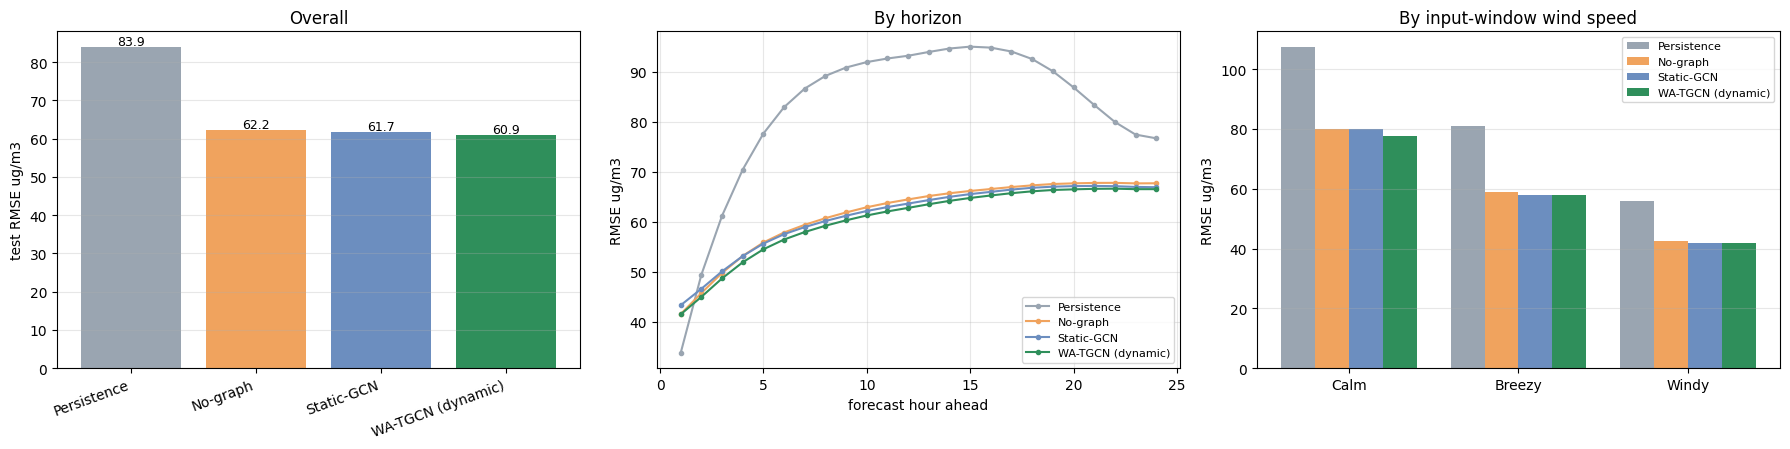

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
cols = {'Persistence': '#9aa5b1', 'No-graph': '#f0a35e', 'Static-GCN': '#6c8ebf', 'WA-TGCN (dynamic)': '#2f8f5b'}

ax[0].bar(range(len(ORDER)), [cmp.loc[m, 'RMSE'] for m in ORDER], color=[cols[m] for m in ORDER])
ax[0].set_xticks(range(len(ORDER))); ax[0].set_xticklabels(ORDER, rotation=20, ha='right')
ax[0].set_ylabel('test RMSE ug/m3'); ax[0].set_title('Overall'); ax[0].grid(axis='y', alpha=.3)
for i, m in enumerate(ORDER):
    ax[0].text(i, cmp.loc[m, 'RMSE'] + 0.6, f"{cmp.loc[m,'RMSE']:.1f}", ha='center', fontsize=9)

for m in ORDER:
    pr = from_log(test_pred[m])
    hz = [np.sqrt(mean_squared_error(ar[:, h, :].ravel(), pr[:, h, :].ravel())) for h in range(HORIZON)]
    ax[1].plot(range(1, 25), hz, marker='o', ms=3, label=m, color=cols[m])
ax[1].set_xlabel('forecast hour ahead'); ax[1].set_ylabel('RMSE ug/m3')
ax[1].set_title('By horizon'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

kk = list(wind_reg); x = np.arange(len(kk)); wd = 0.2
for j, m in enumerate(ORDER):
    ax[2].bar(x + (j-1.5)*wd, [wind_tbl[m][k] for k in kk], wd, label=m, color=cols[m])
ax[2].set_xticks(x); ax[2].set_xticklabels([k.split(' ')[0] for k in kk])
ax[2].set_ylabel('RMSE ug/m3'); ax[2].set_title('By input-window wind speed'); ax[2].grid(axis='y', alpha=.3)
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'baselines_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

In [15]:
out = {
    'note': 'RG6 ablation on the v2 pipeline (26 feat, vol-weighted Huber, 48/24). '
            'Only the wind-aware graph varies. Seeds 42/7/123/2024/999. dynamic = trained v2 checkpoints.',
    'overall': {m: {'rmse': cmp.loc[m, 'RMSE'], 'mae': cmp.loc[m, 'MAE'], 'r2': cmp.loc[m, 'R2']} for m in ORDER},
    'by_horizon': {m: {f'+{h+1}h': round(float(np.sqrt(mean_squared_error(
                      ar[:, h, :].ravel(), from_log(test_pred[m])[:, h, :].ravel()))), 2)
                      for h in range(HORIZON)} for m in ORDER},
    'by_volatility_regime': {m: {k: round(v, 2) for k, v in vol_tbl[m].items()} for m in ORDER},
    'by_wind_regime': {m: {k: round(v, 2) for k, v in wind_tbl[m].items()} for m in ORDER},
    'latency_ms_per_window': {k: round(v, 4) for k, v in lat.items()},
    'compute_scaling_ms_by_N': {str(k): round(v, 4) for k, v in scale.items()},
}
json.dump(out, open(os.path.join(RESULTS_DIR, 'baselines_metrics.json'), 'w'), indent=2)
print('saved  ecotwin_outputs/results/baselines_comparison.csv')
print('saved  ecotwin_outputs/results/baselines_metrics.json')
print('saved  ecotwin_outputs/plots/baselines_comparison.png')
print()
print(cmp[['RMSE', 'MAE', 'R2']].to_string())

saved  ecotwin_outputs/results/baselines_comparison.csv
saved  ecotwin_outputs/results/baselines_metrics.json
saved  ecotwin_outputs/plots/baselines_comparison.png

                    RMSE    MAE      R2
model                                  
Persistence        83.87  56.93  0.3065
No-graph           62.18  40.30  0.6189
Static-GCN         61.73  40.33  0.6243
WA-TGCN (dynamic)  60.88  39.82  0.6346
